## 1. Import Thư viện
Import các thư viện cần thiết cho quá trình chạy benchmark, xử lý dữ liệu và tính toán lỗi (WER).

In [1]:
import os
import gc
import json
import pandas as pd
from tqdm import tqdm
import torch
import torchaudio
import whisperx
import jiwer
import matplotlib.pyplot as plt
import seaborn as sns

## 2. Preprocessing & Exploratory Data Analysis (EDA)
Khám phá tập dữ liệu LibriSpeech (thư mục `test-clean`).
- Lấy danh sách các file audio (`.flac`) và transcript tương ứng.
- Thống kê thời lượng audio, số lượng câu, phân bố độ dài câu.

In [2]:
dataset_path = r"../dataset/LibriSpeech/test-clean"

audio_files = []
transcripts = []
durations = []

print("Đang quét thư mục dataset...")
# Walk qua thư mục test-clean
for root, dirs, files in os.walk(dataset_path):
    # Tìm các file txt chứa transcript
    for file in files:
        if file.endswith(".txt"):
            txt_path = os.path.join(root, file)
            with open(txt_path, 'r', encoding='utf-8') as f:
                lines = f.readlines()
                for line in lines:
                    parts = line.strip().split(" ", 1)
                    if len(parts) == 2:
                        file_id, text = parts
                        flac_path = os.path.join(root, f"{file_id}.flac")
                        if os.path.exists(flac_path):
                            audio_files.append(flac_path)
                            transcripts.append(text)
                            
                            # Lấy metadata thời lượng audio
                            info = torchaudio.info(flac_path)
                            duration = info.num_frames / info.sample_rate
                            durations.append(duration)

df_eda = pd.DataFrame({
    'audio_path': audio_files,
    'transcript': transcripts,
    'duration_sec': durations
})

print(f"Tổng số audio tìm thấy: {len(df_eda)}")
print(f"Tổng thời lượng: {df_eda['duration_sec'].sum() / 3600:.2f} giờ")

df_eda.head()

Đang quét thư mục dataset...
Tổng số audio tìm thấy: 2620
Tổng thời lượng: 5.40 giờ


,audio_path,transcript,duration_sec
0,../dataset/LibriSpeech/test-clean\1089\134686\...,HE HOPED THERE WOULD BE STEW FOR DINNER TURNIP...,10.435000
1,../dataset/LibriSpeech/test-clean\1089\134686\...,STUFF IT INTO YOU HIS BELLY COUNSELLED HIM,3.275000
2,../dataset/LibriSpeech/test-clean\1089\134686\...,AFTER EARLY NIGHTFALL THE YELLOW LAMPS WOULD L...,6.625000
3,../dataset/LibriSpeech/test-clean\1089\134686\...,HELLO BERTIE ANY GOOD IN YOUR MIND,2.680000
4,../dataset/LibriSpeech/test-clean\1089\134686\...,NUMBER TEN FRESH NELLY IS WAITING ON YOU GOOD ...,5.215063


### Trực quan hóa phân bố thời lượng Audio
Hình ảnh dưới đây giúp ta xem phần lớn các file audio trong tập dataset có độ dài bao nhiêu giây.

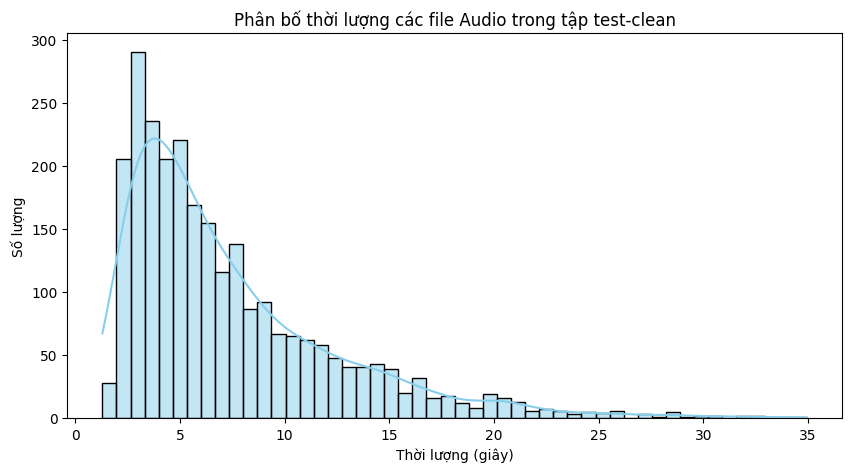

In [3]:
plt.figure(figsize=(10, 5))
sns.histplot(df_eda['duration_sec'], bins=50, kde=True, color='skyblue')
plt.title('Phân bố thời lượng các file Audio trong tập test-clean')
plt.xlabel('Thời lượng (giây)')
plt.ylabel('Số lượng')
plt.show()

### Trực quan hóa độ dài văn bản (Word Count) và Phân bố người nói (Speakers)
Để EDA đầy đủ hơn, chúng ta sẽ phân tích thêm 2 yếu tố:
1. **Độ dài câu (Word Count)**: Số lượng từ trong mỗi transcript.
2. **Sự phân bố dữ liệu theo người nói (Speaker Distribution)**: Đảm bảo tập test có sự cân bằng về khối lượng câu nói giữa các speaker khác nhau.

Tổng số người nói (Speakers) trong tập dataset: 40
Trung bình mỗi câu có: 20.1 từ


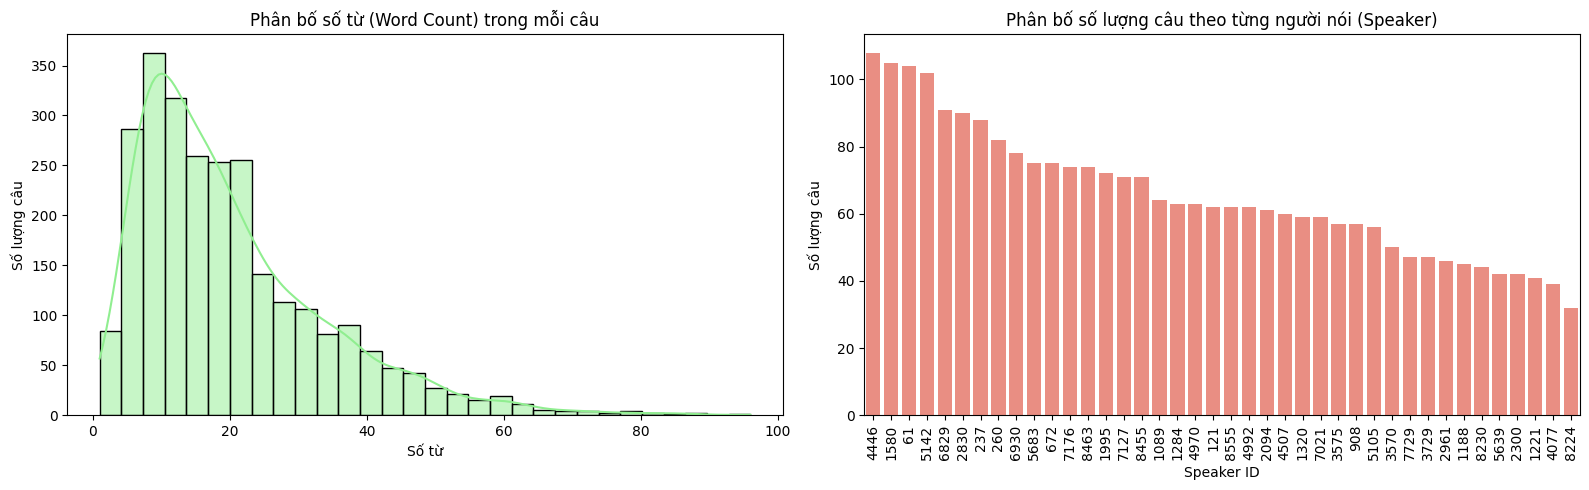

In [4]:
import os

# Tách số từ từ transcript
df_eda['word_count'] = df_eda['transcript'].apply(lambda x: len(x.split()))

# Lấy ID của người nói từ tên file
df_eda['speaker_id'] = df_eda['audio_path'].apply(lambda x: os.path.basename(x).split('-')[0])

print(f"Tổng số người nói (Speakers) trong tập dataset: {df_eda['speaker_id'].nunique()}")
print(f"Trung bình mỗi câu có: {df_eda['word_count'].mean():.1f} từ")

fig, axes = plt.subplots(1, 2, figsize=(16, 5))

# Biểu đồ 1: Phân bố số lượng từ
sns.histplot(df_eda['word_count'], bins=30, kde=True, color='lightgreen', ax=axes[0])
axes[0].set_title('Phân bố số từ (Word Count) trong mỗi câu')
axes[0].set_xlabel('Số từ')
axes[0].set_ylabel('Số lượng câu')

# Biểu đồ 2: Số lượng câu nói của mỗi Speaker (chọn 20 speaker nhiều nhất nếu quá nhiều)
speaker_counts = df_eda['speaker_id'].value_counts()
sns.barplot(x=speaker_counts.index, y=speaker_counts.values, ax=axes[1], color='salmon', order=speaker_counts.index)
axes[1].set_title('Phân bố số lượng câu theo từng người nói (Speaker)')
axes[1].set_xlabel('Speaker ID')
axes[1].set_ylabel('Số lượng câu')
axes[1].tick_params(axis='x', rotation=90)

plt.tight_layout()
plt.show()

## 3. Khởi tạo Model WhisperX
Thiết lập thiết bị (GPU/CPU) và độ phân giải tính toán (compute_type), sau đó load model WhisperX (mặc định thử nghiệm với bản `base`).

In [5]:
device = "cuda" if torch.cuda.is_available() else "cpu"
compute_type = "float16" if device == "cuda" else "int8"

print(f"Đang sử dụng thiết bị: {device.upper()}")
print(f"Kiểu tính toán (Precision): {compute_type}")
print("Đang tải model WhisperX...")

# Chọn size model (ví dụ: 'base', 'small', 'medium', 'large-v2'). Khởi đầu test với 'base' cho nhẹ.
model_size = "base" 
model = whisperx.load_model(model_size, device, compute_type=compute_type)

print("Model đã được load thành công!")

Đang sử dụng thiết bị: CUDA
Kiểu tính toán (Precision): float16
Đang tải model WhisperX...


c:\Users\PHAM MINH DUC\AppData\Local\Programs\Python\Python311\Lib\site-packages\pyannote\audio\core\io.py:48: UserWarning: 
torchcodec is not installed correctly so built-in audio decoding will fail. Solutions are:
* use audio preloaded in-memory as a {'waveform': (channel, time) torch.Tensor, 'sample_rate': int} dictionary;
* fix torchcodec installation. Error message was:

Could not load libtorchcodec. Likely causes:
          1. FFmpeg is not properly installed in your environment. We support
             versions 4, 5, 6 and 7.
          2. The PyTorch version (2.5.1+cu121) is not compatible with
             this version of TorchCodec. Refer to the version compatibility
             table:
             https://github.com/pytorch/torchcodec?tab=readme-ov-file#installing-torchcodec.
          3. Another runtime dependency; see exceptions below.
        The following exceptions were raised as we tried to load libtorchcodec:
        
[start of libtorchcodec loading traceback]
FFmpeg 

2026-07-02 09:12:40 - whisperx.asr - INFO - No language specified, language will be detected for each audio file (increases inference time)
2026-07-02 09:12:40 - whisperx.vads.pyannote - INFO - Performing voice activity detection using Pyannote...


Lightning automatically upgraded your loaded checkpoint from v1.5.4 to v2.6.5. To apply the upgrade to your files permanently, run `python -m lightning.pytorch.utilities.upgrade_checkpoint c:\Users\PHAM MINH DUC\AppData\Local\Programs\Python\Python311\Lib\site-packages\whisperx\assets\pytorch_model.bin`


Model đã được load thành công!


## 4. Chạy thử nghiệm (Inference) trên 1 file
Chúng ta sẽ lấy file audio đầu tiên trong danh sách EDA lúc nãy để đưa vào mô hình WhisperX và in ra kết quả Text để xem nó hoạt động thế nào trước khi chạy toàn bộ.

In [6]:
# Lấy file đầu tiên từ DataFrame đã quét được
test_audio_path = df_eda['audio_path'].iloc[0]
original_transcript = df_eda['transcript'].iloc[0]

print(f"Đang xử lý file: {test_audio_path}")
print(f"Transcript gốc (Ground Truth): {original_transcript}")

# Load audio bằng hàm hỗ trợ của whisperX (Yêu cầu FFmpeg)
audio = whisperx.load_audio(test_audio_path)

# Chạy transcribe
print("Đang chạy WhisperX...")
result = model.transcribe(audio, batch_size=16)

print("--- KẾT QUẢ WHISPERX NHẬN DIỆN ---")
for segment in result["segments"]:
    print(f"[{segment['start']:.2f}s - {segment['end']:.2f}s]: {segment['text']}")


c:\Users\PHAM MINH DUC\AppData\Local\Programs\Python\Python311\Lib\site-packages\pyannote\audio\utils\reproducibility.py:74: ReproducibilityWarning: TensorFloat-32 (TF32) has been disabled as it might lead to reproducibility issues and lower accuracy.
It can be re-enabled by calling
   >>> import torch
   >>> torch.backends.cuda.matmul.allow_tf32 = True
   >>> torch.backends.cudnn.allow_tf32 = True
See https://github.com/pyannote/pyannote-audio/issues/1370 for more details.

  warnings.warn(


Đang xử lý file: ../dataset/LibriSpeech/test-clean\1089\134686\1089-134686-0000.flac
Transcript gốc (Ground Truth): HE HOPED THERE WOULD BE STEW FOR DINNER TURNIPS AND CARROTS AND BRUISED POTATOES AND FAT MUTTON PIECES TO BE LADLED OUT IN THICK PEPPERED FLOUR FATTENED SAUCE
Đang chạy WhisperX...
2026-07-02 09:12:42 - whisperx.asr - WARNING - Audio is shorter than 30s, language detection may be inaccurate
2026-07-02 09:12:43 - whisperx.asr - INFO - Detected language: en (1.00) in first 30s of audio
--- KẾT QUẢ WHISPERX NHẬN DIỆN ---
[0.03s - 10.46s]:  He hoped there would be stew for dinner, turnips and carrots and bruised potatoes and fat mutton pieces to be ladled out in thick, peppered flour-fatten sauce.


## 5. Chạy Benchmark toàn bộ Dataset
Ở bước này, chúng ta sẽ chạy vòng lặp qua toàn bộ dataset.
Vì WhisperX sinh ra văn bản có dấu câu và viết hoa (VD: "Hello, world!"), còn file gốc của LibriSpeech lại không có dấu câu và viết hoa toàn bộ (VD: "HELLO WORLD"), chúng ta cần **Chuẩn hóa (Normalize)** cả hai chuỗi (đưa về chữ thường, xóa dấu câu) trước khi tính WER/CER để đảm bảo công bằng.

Chỉ số đo lường:
1. **WER** (Word Error Rate)
2. **CER** (Character Error Rate)
3. **RTF** (Real-Time Factor)

In [7]:
import time
import re
import jiwer
import pandas as pd
import torchaudio

try:
    from tqdm import tqdm
except ImportError:
    from tqdm import tqdm

# Hàm chuẩn hóa văn bản
def normalize_text(text):
    text = str(text).lower()
    text = re.sub(r'[^\w\s]', '', text) # Xóa dấu câu
    text = re.sub(r'\s+', ' ', text).strip() # Xóa khoảng trắng thừa
    return text

results = []
# df_test = df_eda.copy() 
df_test = df_eda.head(100) 

print(f"Bắt đầu chạy benchmark trên {len(df_test)} files...")

for idx, row in tqdm(df_test.iterrows(), total=len(df_test), desc="Benchmarking"):
    audio_path = row.get('audio_path', row.get('file_path', ''))
    gt_transcript = row.get('transcript', row.get('text', ''))
    
    # Xử lý an toàn cột thời lượng (duration)
    # Nếu không có sẵn trong DataFrame, tự động tính toán bằng torchaudio
    if 'duration' in row and pd.notnull(row['duration']):
        audio_duration = row['duration']
    else:
        try:
            info = torchaudio.info(audio_path)
            audio_duration = info.num_frames / info.sample_rate
        except Exception:
            audio_duration = 0.0 
            
    if not audio_path:
        continue
        
    start_time = time.time()
    
    try:
        # Load audio và chạy transcribe
        audio = whisperx.load_audio(audio_path)
        result = model.transcribe(audio, batch_size=16)
        
        # Ghép các segments lại thành 1 chuỗi kết quả
        pred_transcript = " ".join([seg['text'] for seg in result.get("segments", [])])
        
    except Exception as e:
        print(f"Lỗi khi xử lý file {audio_path}: {e}")
        pred_transcript = ""
        
    end_time = time.time()
    inference_time = end_time - start_time
    
    # Tính toán Metrics
    norm_gt = normalize_text(gt_transcript)
    norm_pred = normalize_text(pred_transcript)
    
    if len(norm_gt) == 0:
        wer_score, cer_score = 0.0, 0.0
    else:
        try:
            wer_score = jiwer.wer(norm_gt, norm_pred)
            cer_score = jiwer.cer(norm_gt, norm_pred)
        except:
            wer_score, cer_score = 1.0, 1.0
            
    rtf = inference_time / audio_duration if audio_duration > 0 else 0
    
    results.append({
        'audio_path': audio_path,
        'duration': audio_duration,
        'gt_transcript': gt_transcript,
        'pred_transcript': pred_transcript,
        'wer': wer_score,
        'cer': cer_score,
        'inference_time': inference_time,
        'rtf': rtf
    })

df_results = pd.DataFrame(results)

if not df_results.empty:
    overall_wer = df_results['wer'].mean()
    overall_cer = df_results['cer'].mean()
    overall_rtf = df_results['rtf'].mean()

    print("\n" + "="*40)
    print("KẾT QUẢ")
    print("="*40)
    print(f"Tổng số file đã xử lý: {len(df_results)}")
    print(f"Trung bình WER: {overall_wer*100:.2f}%")
    print(f"Trung bình CER: {overall_cer*100:.2f}%")
    print(f"Trung bình RTF: {overall_rtf:.4f} (Nghĩa là 1 giây audio tốn {overall_rtf:.4f}s để dịch)")
    print("="*40)

    df_results.to_csv("benchmark_results.csv", index=False, encoding='utf-8')
else:
    print("Không có kết quả nào được tạo ra do lỗi hệ thống.")


Bắt đầu chạy benchmark trên 100 files...


Benchmarking:   0%|          | 0/100 [00:00<?, ?it/s]

2026-07-02 09:12:43 - whisperx.asr - WARNING - Audio is shorter than 30s, language detection may be inaccurate
2026-07-02 09:12:43 - whisperx.asr - INFO - Detected language: en (1.00) in first 30s of audio


Benchmarking:   1%|          | 1/100 [00:00<00:33,  2.97it/s]

2026-07-02 09:12:43 - whisperx.asr - WARNING - Audio is shorter than 30s, language detection may be inaccurate
2026-07-02 09:12:43 - whisperx.asr - INFO - Detected language: en (1.00) in first 30s of audio


Benchmarking:   2%|▏         | 2/100 [00:00<00:25,  3.91it/s]

... (193 outputs left out)

Benchmarking:  99%|█████████▉| 99/100 [00:27<00:00,  3.15it/s]

2026-07-02 09:13:11 - whisperx.asr - WARNING - Audio is shorter than 30s, language detection may be inaccurate
2026-07-02 09:13:11 - whisperx.asr - INFO - Detected language: en (1.00) in first 30s of audio


Benchmarking: 100%|██████████| 100/100 [00:27<00:00,  3.57it/s]


KẾT QUẢ
Tổng số file đã xử lý: 100
Trung bình WER: 5.52%
Trung bình CER: 1.59%
Trung bình RTF: 0.0399 (Nghĩa là 1 giây audio tốn 0.0399s để dịch)


## 6. Trực quan hóa kết quả (Visualization)
Vẽ các biểu đồ để nhìn nhận trực quan hơn về hiệu năng của mô hình.

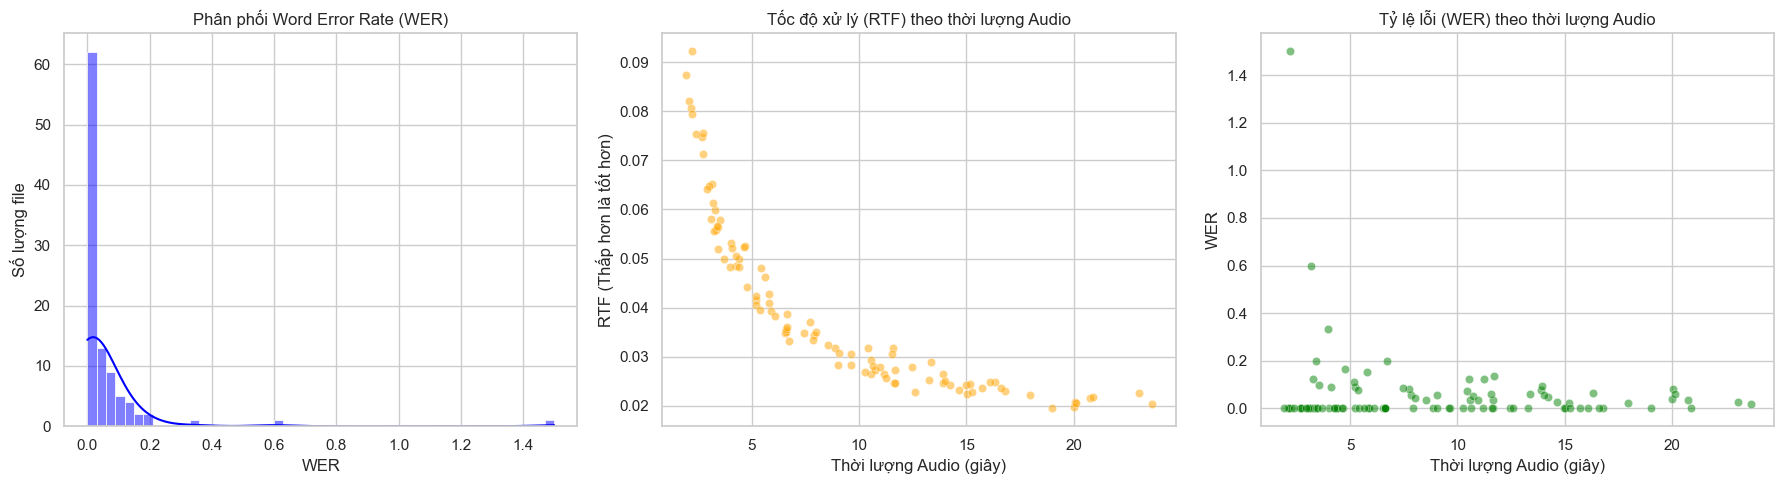

In [8]:
import matplotlib.pyplot as plt
import seaborn as sns

sns.set_theme(style="whitegrid")

fig, axes = plt.subplots(1, 3, figsize=(18, 5))

# 1. Biểu đồ phân phối WER
sns.histplot(df_results['wer'], bins=50, kde=True, ax=axes[0], color='blue')
axes[0].set_title('Phân phối Word Error Rate (WER)')
axes[0].set_xlabel('WER')
axes[0].set_ylabel('Số lượng file')

# 2. Biểu đồ Thời lượng Audio vs RTF
sns.scatterplot(data=df_results, x='duration', y='rtf', ax=axes[1], alpha=0.5, color='orange')
axes[1].set_title('Tốc độ xử lý (RTF) theo thời lượng Audio')
axes[1].set_xlabel('Thời lượng Audio (giây)')
axes[1].set_ylabel('RTF (Thấp hơn là tốt hơn)')

# 3. Biểu đồ Thời lượng Audio vs WER
sns.scatterplot(data=df_results, x='duration', y='wer', ax=axes[2], alpha=0.5, color='green')
axes[2].set_title('Tỷ lệ lỗi (WER) theo thời lượng Audio')
axes[2].set_xlabel('Thời lượng Audio (giây)')
axes[2].set_ylabel('WER')

plt.tight_layout()
plt.show()
